In [1]:
import duckdb, pandas as pd, numpy as np, os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report

con = duckdb.connect("../../spectrum.duckdb")
def q(sql): return con.execute(sql).df()
os.makedirs("../outputs", exist_ok=True)


In [2]:
df = q("""
WITH u AS (
  SELECT customer_id,
         AVG(data_used_gb)     AS avg_gb,
         AVG(avg_speed_mbps)   AS avg_speed,
         AVG(outage_minutes)   AS avg_outage_min,
         AVG(wifi_disconnects) AS avg_disconnects
  FROM monthly_usage GROUP BY 1),
b AS (
  SELECT customer_id,
         AVG(CASE WHEN days_late > 0 THEN 1.0 ELSE 0 END) AS late_rate   -- share of bills paid late
  FROM billing GROUP BY 1),
t AS (
  SELECT customer_id, COUNT(*) AS tickets, AVG(csat_score) AS avg_csat
  FROM support_tickets
  WHERE category <> 'Cancel Request'          -- a cancel call is the outcome, not a predictor
  GROUP BY 1)
SELECT c.customer_id, c.market, c.state, c.plan_name, c.equipment,
       c.tenure_years, c.promo_rolled_2025, c.price_jump, c.list_price, c.promo_end_date,
       c.has_spectrum_mobile, c.has_spectrum_tv, c.autopay, c.paperless,
       c.competitor_fiber_available,
       u.avg_gb, u.avg_speed, u.avg_outage_min, u.avg_disconnects,
       COALESCE(b.late_rate, 0) AS late_rate,
       COALESCE(t.tickets, 0)   AS tickets,
       t.avg_csat,
       c.churned
FROM customers_clean c
LEFT JOIN u USING (customer_id)
LEFT JOIN b USING (customer_id)
LEFT JOIN t USING (customer_id)
""")
df["avg_csat"] = df["avg_csat"].fillna(df["avg_csat"].median())
df.shape

(20000, 23)

In [3]:
features = ["tenure_years", "promo_rolled_2025", "price_jump", "has_spectrum_mobile",
            "has_spectrum_tv", "autopay", "paperless", "competitor_fiber_available",
            "avg_gb", "avg_speed", "avg_outage_min", "avg_disconnects",
            "late_rate", "tickets", "avg_csat"]
X = pd.get_dummies(df[features + ["plan_name", "equipment"]], drop_first=True).astype(float)
y = df["churned"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=7)
print(f"Train: {len(X_train):,}  Test: {len(X_test):,}  Churn rate: {y.mean():.1%}")

Train: 15,000  Test: 5,000  Churn rate: 13.2%


In [4]:
lr = make_pipeline(StandardScaler(),
                   LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                            class_weight="balanced", random_state=7, n_jobs=-1).fit(X_train, y_train)

p_lr = lr.predict_proba(X_test)[:, 1]
p_rf = rf.predict_proba(X_test)[:, 1]
print(f"Logistic Regression AUC: {roc_auc_score(y_test, p_lr):.3f}")
print(f"Random Forest AUC:       {roc_auc_score(y_test, p_rf):.3f}")
print(classification_report(y_test, (p_rf > 0.5).astype(int), digits=3))

Logistic Regression AUC: 0.886
Random Forest AUC:       0.901
              precision    recall  f1-score   support

           0      0.962     0.858     0.907      4338
           1      0.455     0.776     0.574       662

    accuracy                          0.847      5000
   macro avg      0.709     0.817     0.741      5000
weighted avg      0.895     0.847     0.863      5000



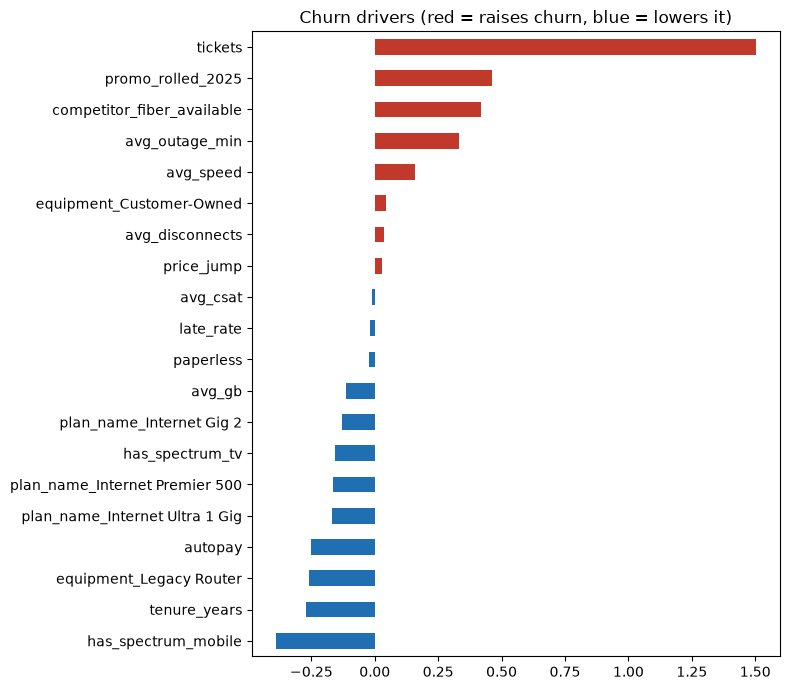

In [5]:
coef = pd.Series(lr[-1].coef_[0], index=X.columns).sort_values()
ax = coef.plot.barh(figsize=(8, 7), color=np.where(coef > 0, "#c0392b", "#1f6fb2"))
ax.set_title("Churn drivers (red = raises churn, blue = lowers it)")
ax.figure.tight_layout()
ax.figure.savefig("../images/churn_model_drivers.png", dpi=150)

In [6]:
lift = pd.DataFrame({"churned": y_test.values, "score": p_rf}).sort_values("score", ascending=False)
lift["decile"] = pd.qcut(lift["score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
capture = (lift.groupby("decile", observed=True).churned.sum().cumsum() / lift.churned.sum()).round(2)
capture

decile
1     0.52
2     0.75
3     0.84
4     0.91
5     0.95
6     0.97
7     0.99
8     1.00
9     1.00
10    1.00
Name: churned, dtype: float64

In [7]:
df["churn_risk_score"] = rf.predict_proba(X)[:, 1].round(3)
df["risk_tier"] = pd.cut(df["churn_risk_score"], [0, 0.3, 0.6, 1],
                         labels=["Low", "Medium", "High"], include_lowest=True)
df[["customer_id", "market", "state", "plan_name", "equipment", "promo_end_date",
    "list_price", "churned", "churn_risk_score", "risk_tier"]].to_csv("../outputs/churn_scores.csv", index=False)
df["risk_tier"].value_counts()


risk_tier
Low       11610
Medium     4989
High       3401
Name: count, dtype: int64

In [9]:
con.close()